In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
# Load the dataset exported from Part 1
df = pd.read_parquet('../data/network_intrusion_sampled.parquet')

# Separate Features (X) and Target Variable (y)
X = df.drop(columns=['Label'])
y = df['Label']

print(f"Full Dataset Shape: {df.shape}")

Full Dataset Shape: (503627, 26)


In [3]:
# We use stratify=y to ensure all classes are proportionally represented
X_temp_train, X_test, y_temp_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y 
)

print(f"Master Train Shape (For Grid Search): {X_temp_train.shape}")
print(f"Locked Test Shape (Do NOT touch yet): {X_test.shape}")

Master Train Shape (For Grid Search): (402901, 25)
Locked Test Shape (Do NOT touch yet): (100726, 25)


In [4]:
# Initialize StandardScaler to center the data (mean=0, variance=1)
scaler = StandardScaler()

# CRITICAL: Fit the scaler ONLY on the training data to prevent data leakage
X_temp_train_scaled = scaler.fit_transform(X_temp_train)

# ONLY transform the test set using the learned parameters
X_test_scaled = scaler.transform(X_test) 

# Convert the resulting numpy arrays back to DataFrames to preserve column names
X_temp_train_scaled = pd.DataFrame(X_temp_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

print("Standardization complete. Data centered to mean=0, variance=1.")

Standardization complete. Data centered to mean=0, variance=1.


In [5]:
import numpy as np
from sklearn.model_selection import PredefinedSplit

# 1. Create the Validation Set from our Temp Train data
# Using test_size=0.25 on 80% of the data gives us a 60/20/20 overall split
X_train, X_val, y_train, y_val = train_test_split(
    X_temp_train, y_temp_train, 
    test_size=0.25, 
    random_state=42, 
    stratify=y_temp_train
)

print(f"Scenario 1 Train Shape: {X_train.shape}")
print(f"Scenario 1 Val Shape:   {X_val.shape}")

# 2. Scale the data WITHOUT leakage
scaler_s1 = StandardScaler()

# Fit ONLY on the new training slice
X_train_scaled = scaler_s1.fit_transform(X_train)

# Transform the validation slice
X_val_scaled = scaler_s1.transform(X_val)

# (We will transform the Master Test set with this scaler at the very end of the project)

Scenario 1 Train Shape: (302175, 25)
Scenario 1 Val Shape:   (100726, 25)


In [6]:
from imblearn.over_sampling import SMOTE

# SMOTE on X_train_scaled only — after scaling, never on val/test
counts = pd.Series(y_train).value_counts().sort_index()

sampling_strategy = {}
for cls_id, cnt in counts.items():
    if cnt < 500:
        sampling_strategy[cls_id] = 500
    elif cnt < 10_000:
        sampling_strategy[cls_id] = 10_000
    # >= 10 000 → left untouched

min_count = int(counts.min())
k_neighbors = min(5, min_count - 1)
print(f"Using k_neighbors={k_neighbors}  (smallest class in train = {min_count})")

smote = SMOTE(sampling_strategy=sampling_strategy, k_neighbors=k_neighbors, random_state=42)

# X_train_scaled is already a numpy array from fit_transform — SMOTE handles it directly
X_train_scaled, y_train = smote.fit_resample(X_train_scaled, y_train)

print(f"\nX_train_scaled shape after SMOTE: {X_train_scaled.shape}")
print("\nClass distribution after SMOTE:")
counts_after = pd.Series(y_train).value_counts().sort_index()
for cls_id, cnt in counts_after.items():
    print(f"  Class {cls_id:>2}:  {cnt:>7,}")

Using k_neighbors=4  (smallest class in train = 5)

X_train_scaled shape after SMOTE: (341543, 25)

Class distribution after SMOTE:
  Class  0:  251,079
  Class  1:      500
  Class  2:   15,359
  Class  3:   10,000
  Class  4:   20,722
  Class  5:   10,000
  Class  6:   10,000
  Class  7:   10,000
  Class  8:      500
  Class  9:      500
  Class 10:   10,883
  Class 11:      500
  Class 12:      500
  Class 13:      500
  Class 14:      500


In [7]:
# Create an array that tells GridSearchCV which rows are Train (-1) and which are Val (0)
split_index = [-1] * len(X_train_scaled) + [0] * len(X_val_scaled)
pds = PredefinedSplit(test_fold=split_index)

# Combine the data back together so GridSearchCV can slice it using our split_index
X_s1_combined = np.vstack((X_train_scaled, X_val_scaled))
y_s1_combined = np.concatenate((y_train, y_val))

print("Predefined Split created successfully for Scenario 1.")

Predefined Split created successfully for Scenario 1.


In [8]:
import json

# Load label mapping from preprocessing step
with open('../data/label_mapping.json', 'r') as f:
    label_mapping = json.load(f)

# Reverse mapping: number -> class name
inverse_mapping = {v: k for k, v in label_mapping.items()}

# Ordered class names for reports
target_names = [inverse_mapping[i] for i in range(len(inverse_mapping))]

print("Loaded class labels:")
print(target_names)

Loaded class labels:
['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# 1. Initialize the model with our imbalance solution
# max_iter is increased to ensure the model converges
log_reg = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)

# 2. Define appropriate hyperparameter ranges
# C: Inverse of regularization strength. Smaller values specify stronger regularization.
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'] # saga is good for large datasets, lbfgs is default
}

# 3. Initialize GridSearchCV USING our PredefinedSplit (cv=pds)
grid_search_lr_s1 = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid_lr,
    cv=pds,             # This forces it to use our specific Train/Val split
    scoring='f1_macro', # F1 macro is excellent for imbalanced datasets
    n_jobs=-1,          # Uses all your CPU cores to speed things up
    verbose=2
)

# 4. Run the Grid Search
print("Starting Grid Search for Logistic Regression (Scenario 1)...")
grid_search_lr_s1.fit(X_s1_combined, y_s1_combined)

print("\n--- Logistic Regression (Scenario 1) Results ---")
print(f"Best Parameters: {grid_search_lr_s1.best_params_}")
print(f"Best Validation F1-Score: {grid_search_lr_s1.best_score_:.4f}")


# Save the best model for later comparison
best_lr_s1 = grid_search_lr_s1.best_estimator_

Starting Grid Search for Logistic Regression (Scenario 1)...
Fitting 1 folds for each of 5 candidates, totalling 5 fits


[CV] END ...............................C=0.01, solver=lbfgs; total time=  21.5s
[CV] END ................................C=0.1, solver=lbfgs; total time=  35.1s
[CV] END ..................................C=1, solver=lbfgs; total time= 1.2min
[CV] END .................................C=10, solver=lbfgs; total time= 1.9min


/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[CV] END ................................C=100, solver=lbfgs; total time= 2.6min

--- Logistic Regression (Scenario 1) Results ---
Best Parameters: {'C': 100, 'solver': 'lbfgs'}
Best Validation F1-Score: 0.4391


/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Create the Pipeline
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        solver='lbfgs',
        max_iter=2000,
        random_state=42
    ))
])

# 2. Parameter Grid
param_grid_lr_cv = {
    'classifier__C': [100],
    'classifier__tol': [1e-2, 1e-3]
}

# 3. Initialize K-Fold and GridSearchCV
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_lr_s2 = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr_cv,
    cv=kf,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2
)

# 4. Run the Grid Search
print("Starting K-Fold Grid Search for Logistic Regression (Scenario 2)...")

grid_search_lr_s2.fit(X_temp_train, y_temp_train)

print("\n--- Logistic Regression Results ---")
print(f"Best Parameters: {grid_search_lr_s2.best_params_}")
print(f"Best Cross-Validation F1-Score: {grid_search_lr_s2.best_score_:.4f}")

# Save best model
best_lr_s2 = grid_search_lr_s2.best_estimator_

Starting K-Fold Grid Search for Logistic Regression (Scenario 2)...
Fitting 5 folds for each of 2 candidates, totalling 10 fits
[CV] END ............classifier__C=100, classifier__tol=0.01; total time=  14.8s
[CV] END ............classifier__C=100, classifier__tol=0.01; total time=  15.6s
[CV] END ............classifier__C=100, classifier__tol=0.01; total time=  18.1s
[CV] END ............classifier__C=100, classifier__tol=0.01; total time=  15.3s
[CV] END ............classifier__C=100, classifier__tol=0.01; total time=  21.6s
[CV] END ...........classifier__C=100, classifier__tol=0.001; total time=  38.1s
[CV] END ...........classifier__C=100, classifier__tol=0.001; total time=  42.3s
[CV] END ...........classifier__C=100, classifier__tol=0.001; total time=  44.8s
[CV] END ...........classifier__C=100, classifier__tol=0.001; total time=  36.9s
[CV] END ...........classifier__C=100, classifier__tol=0.001; total time=  40.5s

--- Logistic Regression Results ---
Best Parameters: {'classi

EVALUATING SCENARIO 1 (Train/Validation Split Model)
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.76      0.86     83694
                       Bot       0.01      0.97      0.02        78
                      DDoS       0.89      1.00      0.94      5120
             DoS GoldenEye       0.38      0.94      0.54       411
                  DoS Hulk       0.94      0.94      0.94      6908
          DoS Slowhttptest       0.21      0.95      0.35       209
             DoS slowloris       0.13      0.92      0.23       215
               FTP-Patator       0.50      1.00      0.67       237
                Heartbleed       0.25      1.00      0.40         1
              Infiltration       0.03      1.00      0.05         7
                  PortScan       0.42      1.00      0.59      3628
               SSH-Patator       0.22      0.90      0.35       129
  Web Attack � Brute Force       0.01      0.05      0.01     

/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


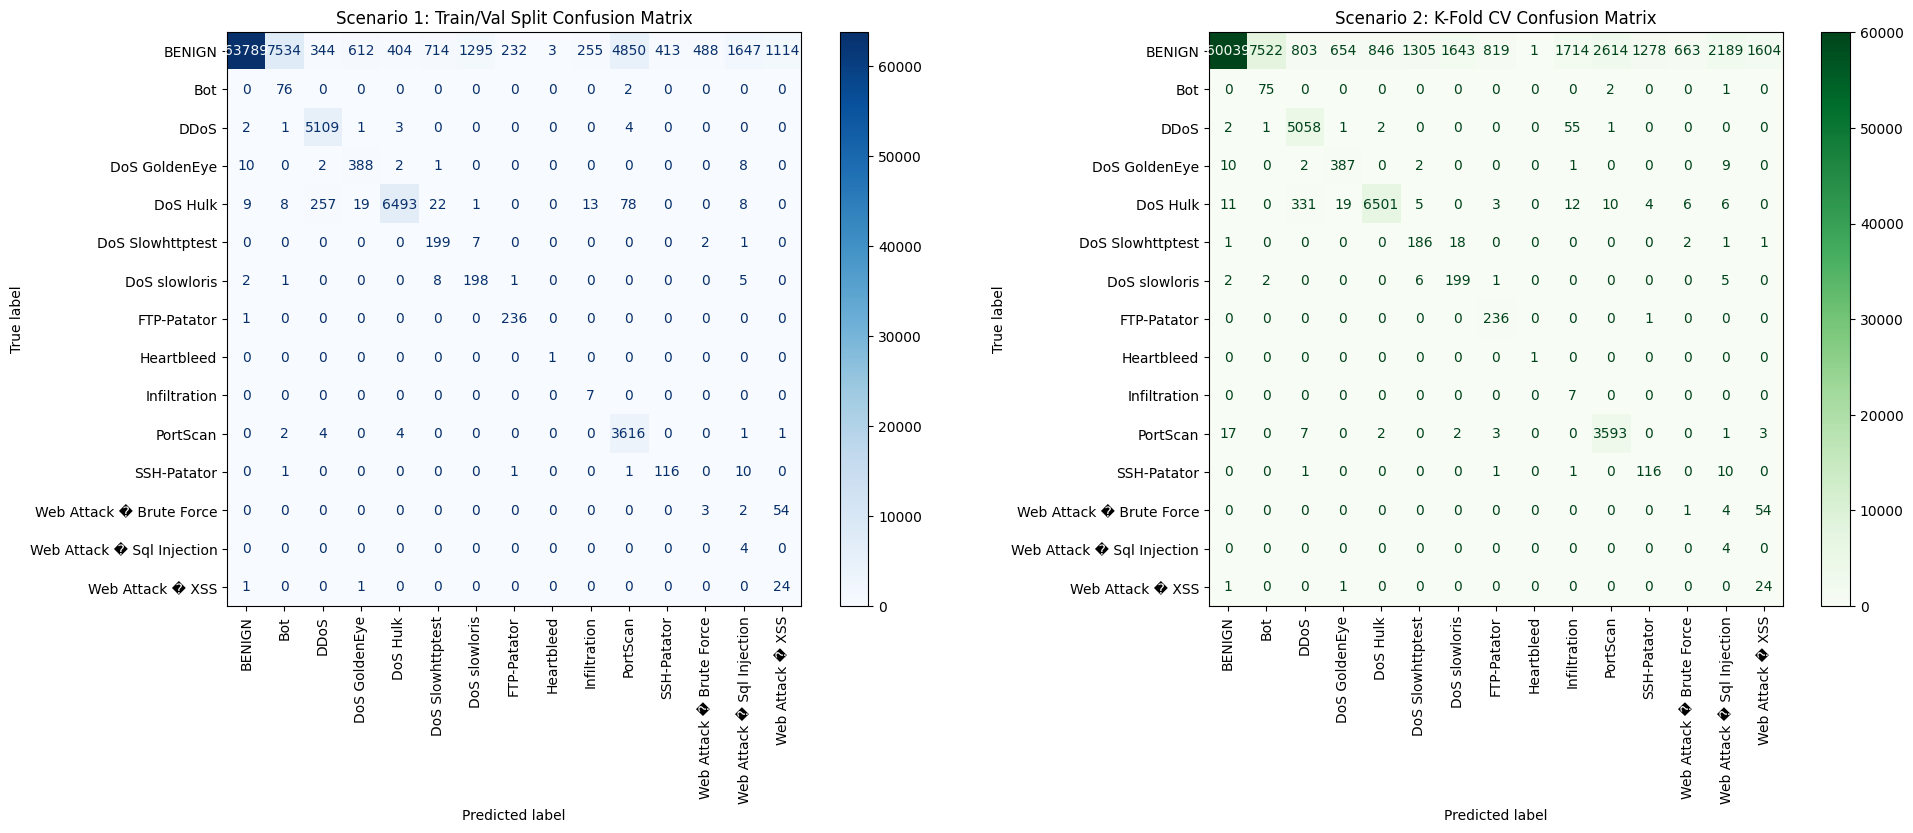

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Readable class names
target_names = [inverse_mapping[i] for i in range(len(inverse_mapping))]
labels = list(range(len(target_names)))  # numeric class ids in fixed order

print("=" * 60)
print("EVALUATING SCENARIO 1 (Train/Validation Split Model)")
print("=" * 60)

# Scenario 1 prediction (scaled test set, because model is not a pipeline)
y_pred_s1 = best_lr_s1.predict(X_test_scaled)
print(classification_report(y_test, y_pred_s1, target_names=target_names))

print("\n" + "=" * 60)
print("EVALUATING SCENARIO 2 (K-Fold Cross-Validation Model)")
print("=" * 60)

# Scenario 2 prediction (raw test set, pipeline handles scaling)
y_pred_s2 = best_lr_s2.predict(X_test)
print(classification_report(y_test, y_pred_s2, target_names=target_names))

# Confusion matrices
cm_s1 = confusion_matrix(y_test, y_pred_s1, labels=labels)
cm_s2 = confusion_matrix(y_test, y_pred_s2, labels=labels)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_s1, display_labels=target_names)
disp1.plot(ax=axes[0], cmap="Blues", xticks_rotation=90, colorbar=True, values_format="d")
axes[0].set_title("Scenario 1: Train/Val Split Confusion Matrix")

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_s2, display_labels=target_names)
disp2.plot(ax=axes[1], cmap="Greens", xticks_rotation=90, colorbar=True, values_format="d")
axes[1].set_title("Scenario 2: K-Fold CV Confusion Matrix")

for ax in axes:
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# 1. Initialize the model with imbalance solution
tree_clf = DecisionTreeClassifier(class_weight='balanced', random_state=42)

# 2. Define hyperparameter ranges
param_grid_dt = {
    'max_depth':         [20, 26, None],
    'min_samples_split': [2, 5, 20],
    'min_samples_leaf':  [1, 3, 5],
    'criterion':         ['gini']
}

# 3. Initialize GridSearchCV using the SAME PredefinedSplit as Logistic Regression
grid_search_dt_s1 = GridSearchCV(
    estimator=tree_clf,
    param_grid=param_grid_dt,
    cv=pds,             # Same split as LR
    scoring='f1_macro', # Same metric as LR
    n_jobs=-1,
    verbose=2
)

# 4. Run the Grid Search on the SAME combined data
print("Starting Grid Search for Decision Tree (Scenario 1)...")
grid_search_dt_s1.fit(X_s1_combined, y_s1_combined)

print("\n--- Decision Tree (Scenario 1) Results ---")
print(f"Best Parameters: {grid_search_dt_s1.best_params_}")
print(f"Best Validation F1-Score: {grid_search_dt_s1.best_score_:.4f}")

# Save the best model for later comparison
best_dt_s1 = grid_search_dt_s1.best_estimator_

print(f"Actual tree depth: {best_dt_s1.get_depth()}")
print(f"Total number of leaves: {best_dt_s1.get_n_leaves()}")
print(f"Total number of nodes: {best_dt_s1.tree_.node_count}")

print(f"Training samples: {len(X_train)}")
print(f"Number of leaves: {best_dt_s1.get_n_leaves()}")
print(f"Ratio: {len(X_train) / best_dt_s1.get_n_leaves():.1f} samples per leaf")

Starting Grid Search for Decision Tree (Scenario 1)...
Fitting 1 folds for each of 27 candidates, totalling 27 fits
[CV] END criterion=gini, max_depth=20, min_samples_leaf=1, min_samples_split=2; total time=   6.3s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=5, min_samples_split=5; total time=   6.0s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=3, min_samples_split=2; total time=   6.1s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=5, min_samples_split=2; total time=   6.2s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=3, min_samples_split=5; total time=   6.2s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=1, min_samples_split=5; total time=   6.4s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=3, min_samples_split=20; total time=   6.5s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=1, min_samples_split=20; total time=   6.6s
[CV] END criterion=gini, max_depth=20, min_samples_leaf=5, min_samples_split=20; total tim

In [14]:
importances = best_dt_s1.feature_importances_
feature_names = X.columns  # or whatever your feature list is

import pandas as pd
feat_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

print(feat_df.head(10))

                        feature  importance
0              Destination Port    0.281342
6         Bwd Packet Length Max    0.138040
21      Init_Win_bytes_backward    0.102482
4         Fwd Packet Length Max    0.082192
10                 Flow IAT Std    0.080208
9                 Flow IAT Mean    0.058160
11                  Fwd IAT Min    0.053151
3   Total Length of Fwd Packets    0.039372
14                  Bwd IAT Std    0.033850
22                  Active Mean    0.030532


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 1. Create the Pipeline
pipeline_dt = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# 2. Parameter Grid
param_grid_dt_cv = {
    'classifier__max_depth':         [20, 26],
    'classifier__min_samples_split': [2, 5, 20],
    'classifier__min_samples_leaf':  [1, 3, 5],
    'classifier__criterion':         ['gini', 'entropy']
}

# 3. Initialize K-Fold and GridSearchCV
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_dt_s2 = GridSearchCV(
    estimator=pipeline_dt,
    param_grid=param_grid_dt_cv,
    cv=kf,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2
)

# 4. Run the Grid Search
print("Starting K-Fold Grid Search for Decision Tree (Scenario 2)...")
grid_search_dt_s2.fit(X_temp_train, y_temp_train)

print("\n--- Decision Tree (Scenario 2) Results ---")
print(f"Best Parameters: {grid_search_dt_s2.best_params_}")
print(f"CV F1 (used for param selection only): {grid_search_dt_s2.best_score_:.4f}")

# Save best model
best_dt_s2 = grid_search_dt_s2.best_estimator_

dt_s2 = best_dt_s2.named_steps['classifier']
print(dt_s2.get_depth())
print(dt_s2.get_n_leaves())
print(dt_s2.tree_.node_count)

dt_s2 = best_dt_s2.named_steps['classifier']

print(f"Actual tree depth: {dt_s2.get_depth()}")
print(f"Total number of leaves: {dt_s2.get_n_leaves()}")
print(f"Total number of nodes: {dt_s2.tree_.node_count}")

print(f"Training samples: {len(X_temp_train)}")
print(f"Number of leaves: {dt_s2.get_n_leaves()}")
print(f"Ratio: {len(X_temp_train) / dt_s2.get_n_leaves():.1f} samples per leaf")

Starting K-Fold Grid Search for Decision Tree (Scenario 2)...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
[CV] END classifier__criterion=gini, classifier__max_depth=20, classifier__min_samples_leaf=1, classifier__min_samples_split=2; total time=   4.6s
[CV] END classifier__criterion=gini, classifier__max_depth=20, classifier__min_samples_leaf=1, classifier__min_samples_split=2; total time=   4.8s
[CV] END classifier__criterion=gini, classifier__max_depth=20, classifier__min_samples_leaf=1, classifier__min_samples_split=5; total time=   5.0s
[CV] END classifier__criterion=gini, classifier__max_depth=20, classifier__min_samples_leaf=1, classifier__min_samples_split=2; total time=   5.1s
[CV] END classifier__criterion=gini, classifier__max_depth=20, classifier__min_samples_leaf=1, classifier__min_samples_split=5; total time=   5.1s
[CV] END classifier__criterion=gini, classifier__max_depth=20, classifier__min_samples_leaf=1, classifier__min_samples_split=2; total time=  

In [16]:
# Scenario 2 (pipeline) -> extract decision tree step first
dt_s2 = best_dt_s2.named_steps['classifier']   # change key if your step name differs

importances = dt_s2.feature_importances_
feature_names = X.columns  # original feature names

import pandas as pd
feat_df_s2 = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

print(feat_df_s2.head(10))

                        feature  importance
0              Destination Port    0.482518
21      Init_Win_bytes_backward    0.136166
6         Bwd Packet Length Max    0.098770
20       Init_Win_bytes_forward    0.052417
17                Bwd Packets/s    0.049673
11                  Fwd IAT Min    0.032217
7                  Flow Bytes/s    0.030457
3   Total Length of Fwd Packets    0.025612
9                 Flow IAT Mean    0.025345
10                 Flow IAT Std    0.012153


DECISION TREE - EVALUATING SCENARIO 1 (Train/Val Split)
                            precision    recall  f1-score   support

                    BENIGN       0.91      0.99      0.95     83694
                       Bot       1.00      0.40      0.57        78
                      DDoS       0.99      0.93      0.96      5120
             DoS GoldenEye       0.94      0.85      0.90       411
                  DoS Hulk       0.75      0.18      0.29      6908
          DoS Slowhttptest       0.46      0.39      0.42       209
             DoS slowloris       0.36      0.73      0.48       215
               FTP-Patator       0.98      0.69      0.81       237
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       0.00      0.00      0.00         7
                  PortScan       0.86      0.54      0.66      3628
               SSH-Patator       0.00      0.00      0.00       129
  Web Attack � Brute Force       0.42      0.22      0.29  

/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/andreaskarama

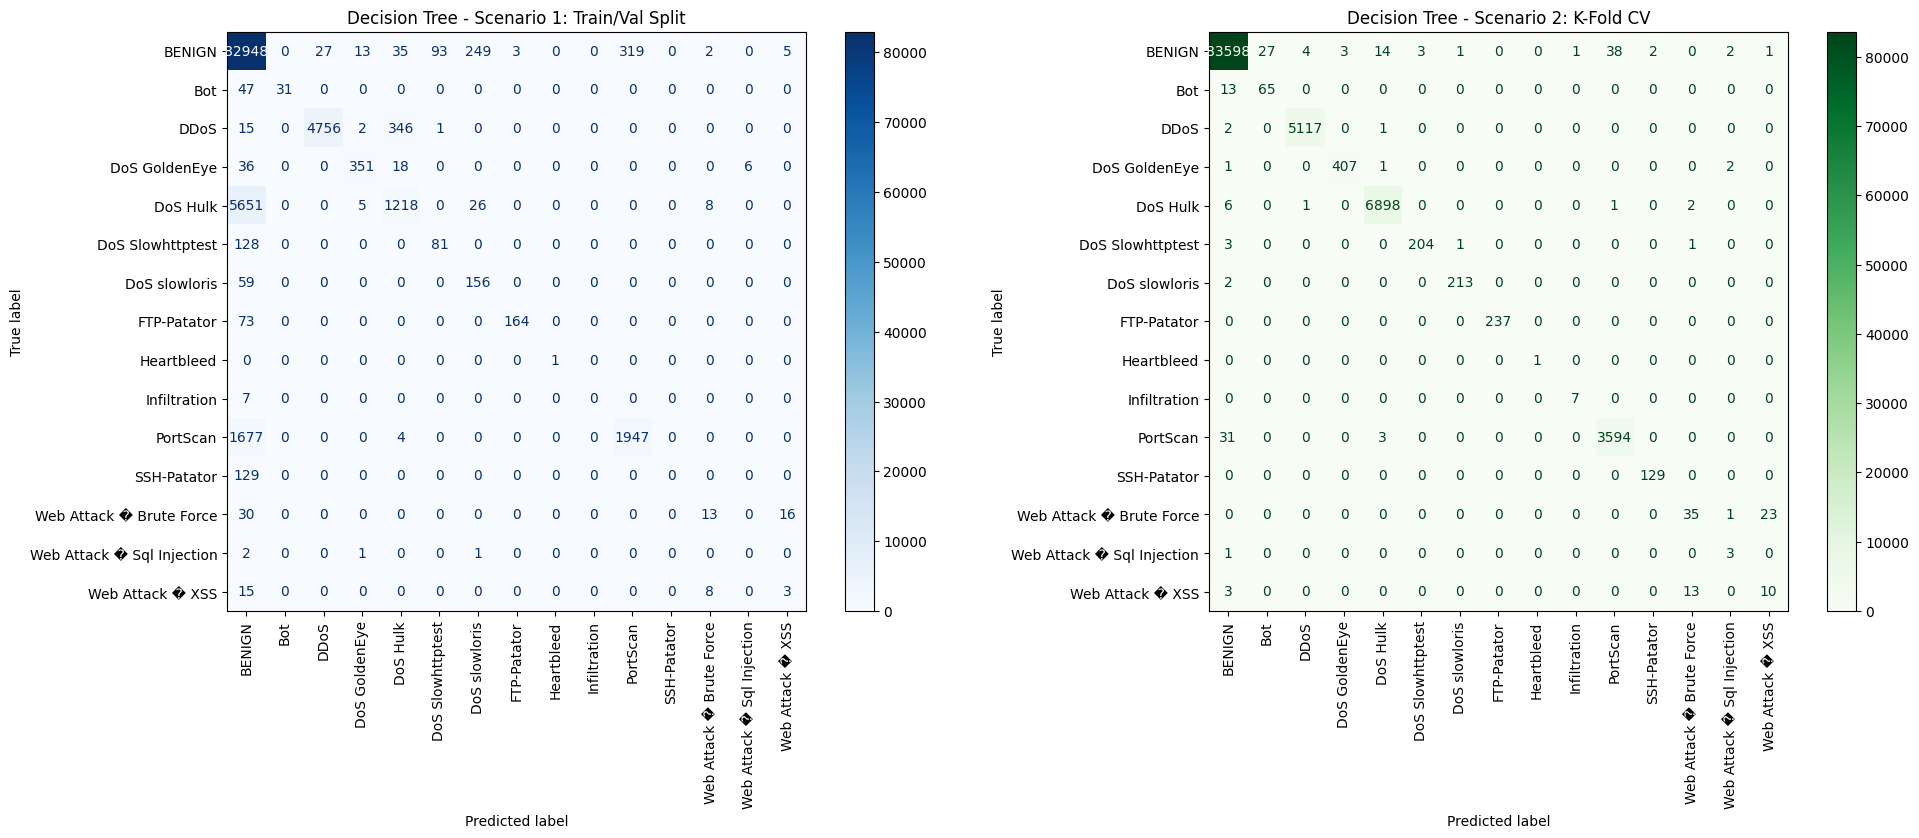

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Readable class names
target_names = [inverse_mapping[i] for i in range(len(inverse_mapping))]
labels = list(range(len(target_names)))

print("=" * 60)
print("DECISION TREE - EVALUATING SCENARIO 1 (Train/Val Split)")
print("=" * 60)
# Scenario 1 prediction (scaled test set, model is not a pipeline)
y_pred_dt_s1 = best_dt_s1.predict(X_test_scaled)
print(classification_report(y_test, y_pred_dt_s1, target_names=target_names))

print("\n" + "=" * 60)
print("DECISION TREE - EVALUATING SCENARIO 2 (K-Fold CV)")
print("=" * 60)
# Scenario 2 prediction (raw test set, pipeline handles scaling)
y_pred_dt_s2 = best_dt_s2.predict(X_test)
print(classification_report(y_test, y_pred_dt_s2, target_names=target_names))

# Confusion matrices
cm_dt_s1 = confusion_matrix(y_test, y_pred_dt_s1, labels=labels)
cm_dt_s2 = confusion_matrix(y_test, y_pred_dt_s2, labels=labels)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_dt_s1, display_labels=target_names)
disp1.plot(ax=axes[0], cmap="Blues", xticks_rotation=90, colorbar=True, values_format="d")
axes[0].set_title("Decision Tree - Scenario 1: Train/Val Split")

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_dt_s2, display_labels=target_names)
disp2.plot(ax=axes[1], cmap="Greens", xticks_rotation=90, colorbar=True, values_format="d")
axes[1].set_title("Decision Tree - Scenario 2: K-Fold CV")

for ax in axes:
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# 1. Initialize the Random Forest model with class imbalance solution
# We use random_state=42 for reproducibility across runs
rf_clf = RandomForestClassifier(class_weight='balanced', random_state=42)

# 2. Define hyperparameter ranges for Random Forest
# Note: Random Forests can take a while to train, so we are keeping the parameter 
# space reasonable. n_estimators controls the number of trees.
param_grid_rf = {
    'n_estimators':      [50, 100, 200],
    'max_depth':         [10, 15, None],
    'min_samples_split': [2,],
    'min_samples_leaf':  [1, 3]
}

# 3. Initialize GridSearchCV using the SAME PredefinedSplit as previous models
grid_search_rf_s1 = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid_rf,
    cv=pds,             # This forces it to use the exact same Train/Val split
    scoring='f1_macro', # Important for the imbalanced dataset
    n_jobs=-1,          # Utilize all CPU cores
    verbose=2
)

# 4. Run the Grid Search on the SAME combined data
print("Starting Grid Search for Random Forest (Scenario 1)...")
grid_search_rf_s1.fit(X_s1_combined, y_s1_combined)

print("\n--- Random Forest (Scenario 1) Results ---")
print(f"Best Parameters: {grid_search_rf_s1.best_params_}")
print(f"Best Validation F1-Score: {grid_search_rf_s1.best_score_:.4f}")

# Save the best model for later comparison and evaluation
best_rf_s1 = grid_search_rf_s1.best_estimator_

# Print out some basic characteristics of the optimal ensemble
print(f"\nFinal Model details:")
print(f"Number of trees chosen: {best_rf_s1.n_estimators}")
print(f"Max depth allowed: {best_rf_s1.max_depth}")

Starting Grid Search for Random Forest (Scenario 1)...
Fitting 1 folds for each of 18 candidates, totalling 18 fits
[CV] END max_depth=10, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=  36.4s
[CV] END max_depth=10, min_samples_leaf=3, min_samples_split=2, n_estimators=50; total time=  36.4s
[CV] END max_depth=15, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=  41.4s
[CV] END max_depth=10, min_samples_leaf=3, min_samples_split=2, n_estimators=100; total time= 1.2min
[CV] END max_depth=10, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time= 1.2min
[CV] END max_depth=15, min_samples_leaf=3, min_samples_split=2, n_estimators=50; total time=  42.8s
[CV] END max_depth=15, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time= 1.4min
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=  44.3s
[CV] END max_depth=15, min_samples_leaf=3, min_samples_split=2, n_estimators=10

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# 1. Create the Pipeline
pipeline_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# 2. Parameter Grid
# Note: Since we are using a pipeline, we MUST prefix the hyperparameters 
# with 'classifier__' so GridSearchCV knows which step they belong to.
param_grid_rf_cv = {
    'classifier__n_estimators':      [50, 100, 200],
    'classifier__max_depth':         [10, 15, None],
    'classifier__min_samples_split': [2],
    'classifier__min_samples_leaf':  [1]
}

# 3. Initialize K-Fold and GridSearchCV
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_rf_s2 = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf_cv,
    cv=kf,
    scoring='f1_macro', # F1 macro for imbalanced datasets
    n_jobs=-1,
    verbose=2
)

# 4. Run the Grid Search on the Temp Train set
print("Starting K-Fold Grid Search for Random Forest (Scenario 2)...")
grid_search_rf_s2.fit(X_temp_train, y_temp_train)

print("\n--- Random Forest (Scenario 2) Results ---")
print(f"Best Parameters: {grid_search_rf_s2.best_params_}")
print(f"CV F1-Score (used for param selection only): {grid_search_rf_s2.best_score_:.4f}")

# Save best model pipeline
best_rf_s2 = grid_search_rf_s2.best_estimator_

# Extract the actual Random Forest model from the pipeline to see its details
rf_s2_model = best_rf_s2.named_steps['classifier']
print(f"\nFinal Model Details:")
print(f"Number of estimators (trees): {rf_s2_model.n_estimators}")
print(f"Max depth allowed: {rf_s2_model.max_depth}")

Starting K-Fold Grid Search for Random Forest (Scenario 2)...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV] END classifier__max_depth=10, classifier__min_samples_leaf=1, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  30.5s
[CV] END classifier__max_depth=10, classifier__min_samples_leaf=1, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  30.8s
[CV] END classifier__max_depth=10, classifier__min_samples_leaf=1, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  30.8s
[CV] END classifier__max_depth=10, classifier__min_samples_leaf=1, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  30.9s
[CV] END classifier__max_depth=10, classifier__min_samples_leaf=1, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  30.9s
[CV] END classifier__max_depth=10, classifier__min_samples_leaf=1, classifier__min_samples_split=2, classifier__n_estimators=100; total ti

RANDOM FOREST - EVALUATING SCENARIO 1 (Train/Val Split)


/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/andreaskarama

                            precision    recall  f1-score   support

                    BENIGN       0.96      1.00      0.98     83694
                       Bot       0.62      0.41      0.49        78
                      DDoS       1.00      0.64      0.78      5120
             DoS GoldenEye       1.00      0.98      0.99       411
                  DoS Hulk       0.99      0.98      0.99      6908
          DoS Slowhttptest       0.98      0.44      0.61       209
             DoS slowloris       1.00      0.98      0.99       215
               FTP-Patator       0.99      1.00      1.00       237
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       0.00      0.00      0.00         7
                  PortScan       0.97      0.54      0.70      3628
               SSH-Patator       1.00      0.83      0.91       129
  Web Attack � Brute Force       0.80      0.14      0.23        59
Web Attack � Sql Injection       1.00      0.25

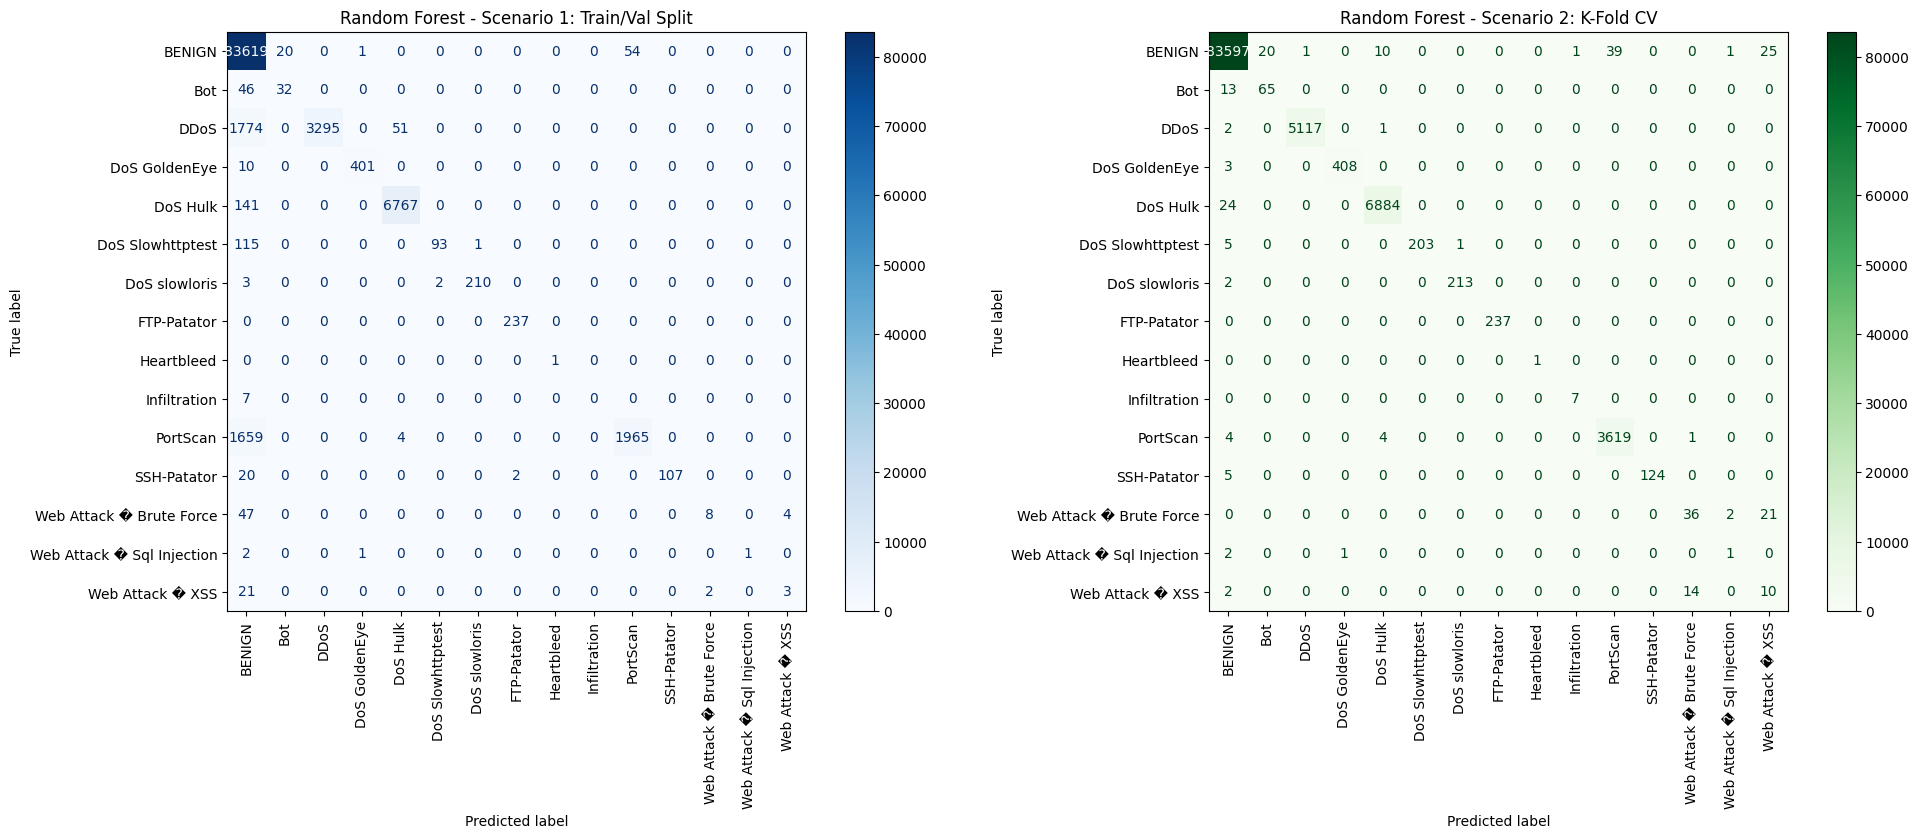

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


# Readable class names
target_names = [inverse_mapping[i] for i in range(len(inverse_mapping))]
labels = list(range(len(target_names)))  # numeric class ids in fixed order

print("=" * 60)
print("RANDOM FOREST - EVALUATING SCENARIO 1 (Train/Val Split)")
print("=" * 60)
# Scenario 1 prediction (scaled test set, because the model itself is not a pipeline)
y_pred_rf_s1 = best_rf_s1.predict(X_test_scaled)
print(classification_report(y_test, y_pred_rf_s1, target_names=target_names))

print("\n" + "=" * 60)
print("RANDOM FOREST - EVALUATING SCENARIO 2 (K-Fold CV)")
print("=" * 60)
# Scenario 2 prediction (raw test set, because the pipeline automatically handles scaling)
y_pred_rf_s2 = best_rf_s2.predict(X_test)
print(classification_report(y_test, y_pred_rf_s2, target_names=target_names))

# Confusion matrices
cm_rf_s1 = confusion_matrix(y_test, y_pred_rf_s1, labels=labels)
cm_rf_s2 = confusion_matrix(y_test, y_pred_rf_s2, labels=labels)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot Scenario 1 (Blues)
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_rf_s1, display_labels=target_names)
disp1.plot(ax=axes[0], cmap="Blues", xticks_rotation=90, colorbar=True, values_format="d")
axes[0].set_title("Random Forest - Scenario 1: Train/Val Split")

# Plot Scenario 2 (Greens)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_rf_s2, display_labels=target_names)
disp2.plot(ax=axes[1], cmap="Greens", xticks_rotation=90, colorbar=True, values_format="d")
axes[1].set_title("Random Forest - Scenario 2: K-Fold CV")

# Set common labels
for ax in axes:
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()